# MLP con Dropout: clasificación de objetos interactuados en tres clases

Este notebook entrena y evalúa únicamente una red neuronal compacta con dropout para predecir `ObjetosInteractuadosCorrectamente` en clases **baja**, **media** y **alta**. Los límites se calculan como terciles usando solo grupos de origen de entrenamiento.

La separación se realiza por `source_session_id` para mantener juntas las filas derivadas de una misma sesión. Se usan terciles provisionales solo para equilibrar la separación de grupos; los cortes finales de las clases se vuelven a calcular exclusivamente con train. Se excluyen `CantAciertasTotales` y `Precision`, ya que son medidas de resultado estrechamente relacionadas con los objetos acertados. Las métricas son exploratorias y no representan validación clínica.

In [1]:
from pathlib import Path
import sys

APP_ROOT_CANDIDATES = [Path.cwd() / 'neuroflex-dashboard-master', Path.cwd()]
APP_ROOT = next((p for p in APP_ROOT_CANDIDATES if (p / 'ml' / 'dropout_mlp.py').is_file()), None)
if APP_ROOT is None:
    raise FileNotFoundError('No se encontró el directorio del dashboard con ml/dropout_mlp.py')
sys.path.insert(0, str(APP_ROOT))
from ml.dropout_mlp import DropoutMLPClassifier
import warnings
import json
import hashlib
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')
SEED = 42
TARGET = 'ObjetosInteractuadosCorrectamente'
GROUP = 'source_session_id'
DATA_FILENAME = 'neuroflex_dataset_augmented.csv'
DATA_PATH_CANDIDATES = [Path.cwd() / DATA_FILENAME, Path.cwd() / 'archivos_neuroflex' / DATA_FILENAME, Path.cwd().parent / 'archivos_neuroflex' / DATA_FILENAME]
DATA_PATH = next((p for p in DATA_PATH_CANDIDATES if p.is_file()), DATA_PATH_CANDIDATES[1])
print('Archivo esperado:', DATA_PATH.resolve())

Archivo esperado: C:\Users\cristobal\Downloads\NeuroflexW-main\archivos_neuroflex\neuroflex_dataset_augmented.csv


In [2]:
if not DATA_PATH.is_file():
    searched = '\n'.join(str(p.resolve()) for p in DATA_PATH_CANDIDATES)
    raise FileNotFoundError(f'No se encontró {DATA_FILENAME}. Directorio actual: {Path.cwd()}\nRutas revisadas:\n{searched}')
DATA_PATH = DATA_PATH.resolve()
df = pd.read_csv(DATA_PATH)
required = {TARGET, GROUP}
missing = required.difference(df.columns)
if missing:
    raise KeyError(f'Faltan columnas necesarias: {sorted(missing)}')
df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
df = df.dropna(subset=[TARGET, GROUP]).copy()
if df[GROUP].nunique() < 5:
    raise ValueError('Se necesitan al menos cinco grupos de origen')
print(f'Dataset: {DATA_PATH}')
print(f'Filas: {len(df):,} | grupos de origen: {df[GROUP].nunique()}')
display(df[TARGET].describe().to_frame().round(2))

Dataset: C:\Users\cristobal\Downloads\NeuroflexW-main\archivos_neuroflex\neuroflex_dataset_augmented.csv
Filas: 6,000 | grupos de origen: 117


,ObjetosInteractuadosCorrectamente
count,6000.00
mean,4.51
std,3.07
min,0.00
25%,2.00
50%,4.00
75%,7.00
max,9.00


# Datos y particiones

In [3]:
# Crear particiones estratificadas por grupo de origen
groups = df[GROUP].astype('string')
all_group_target = df.groupby(GROUP)[TARGET].first()
split_q1, split_q2 = all_group_target.quantile([1/3, 2/3]).tolist()
split_strata = pd.cut(
    df[TARGET],
    bins=[-np.inf, split_q1, split_q2, np.inf],
    labels=[0, 1, 2],
).astype(int)

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_val_idx, test_idx = next(outer.split(df, split_strata, groups))
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
train_rel, val_rel = next(
    inner.split(
        df.iloc[train_val_idx],
        split_strata.iloc[train_val_idx],
        groups.iloc[train_val_idx],
    )
)
train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]
train_df, val_df, test_df = (
    df.iloc[train_idx].copy(),
    df.iloc[val_idx].copy(),
    df.iloc[test_idx].copy(),
)

g_train, g_val, g_test = (
    set(part[GROUP].astype(str))
    for part in (train_df, val_df, test_df)
)
assert g_train.isdisjoint(g_val)
assert g_train.isdisjoint(g_test)
assert g_val.isdisjoint(g_test)

## Definir las clases

In [4]:
# Crear las tres clases usando solo los grupos de entrenamiento
train_group_target = train_df.groupby(GROUP)[TARGET].first()
q1, q2 = train_group_target.quantile([1/3, 2/3]).tolist()
if not q1 < q2:
    raise ValueError(f'{TARGET} no tiene suficientes valores distintos en train')

class_names = ['Baja', 'Media', 'Alta']
class_to_id = {name: idx for idx, name in enumerate(class_names)}

def encode_target(values):
    bins = pd.cut(
        values,
        bins=[-np.inf, q1, q2, np.inf],
        labels=class_names,
        include_lowest=True,
    )
    return bins.map(class_to_id).astype(int)

y_train, y_val, y_test = (
    encode_target(part[TARGET])
    for part in (train_df, val_df, test_df)
)

In [5]:
print(f'Cortes de {TARGET}: Baja <= {q1:.2f} | Media <= {q2:.2f} | Alta > {q2:.2f}')
print(f'Train: {len(train_df):,} filas / {len(g_train)} grupos')
print(f'Validación: {len(val_df):,} filas / {len(g_val)} grupos')
print(f'Test: {len(test_df):,} filas / {len(g_test)} grupos')

display(pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'validación': y_val.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).rename(index=dict(enumerate(class_names))).fillna(0).round(3))

for name, labels in [('train', y_train), ('validación', y_val), ('test', y_test)]:
    if set(labels.unique()) != {0, 1, 2}:
        raise ValueError(f'La partición {name} no contiene las tres clases')

Cortes de ObjetosInteractuadosCorrectamente: Baja <= 3.00 | Media <= 6.00 | Alta > 6.00
Train: 3,811 filas / 74 grupos
Validación: 973 filas / 19 grupos
Test: 1,216 filas / 24 grupos


,train,validación,test
ObjetosInteractuadosCorrectamente,,,
Baja,0.381,0.377,0.381
Media,0.313,0.313,0.299
Alta,0.306,0.309,0.320


In [6]:
# Quitar objetivo, identificadores y métricas de resultado relacionadas
excluded = {TARGET, GROUP, 'session_id', 'timestamp', 'date', 'name', 'rut', 'patient_updated_at', 'CantAciertasTotales', 'Precision'}
feature_cols = [c for c in df.columns if c not in excluded]
if not feature_cols:
    raise ValueError('No quedaron predictores disponibles')
categorical_cols = [c for c in ['dominant_hand', 'TipoEscena'] if c in feature_cols]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]
def make_X(part):
    X = part[feature_cols].copy()
    for col in numeric_cols:
        X[col] = pd.to_numeric(X[col], errors='coerce')
    return X
X_train, X_val, X_test = (make_X(part) for part in (train_df, val_df, test_df))
print('Predictores:', feature_cols)
print('Variables categóricas:', categorical_cols)

Predictores: ['dominant_hand', 'TiempoRespuestaPararse', 'TiempoActivoTarea', 'TiempoRespuestaPregunta1', 'TiempoRespuestaPregunta2', 'TiempoRespuestaPregunta3', 'TiempoCapturarNumero', 'TiempoTutorial', 'TipoEscena']
Variables categóricas: ['dominant_hand', 'TipoEscena']


# Preparar variables

In [7]:
transformers = []
if numeric_cols:
    transformers.append(('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols))
if categorical_cols:
    transformers.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols))
preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')

## Red neuronal con dropout

In [8]:
# La clase vive en ml/dropout_mlp.py para que el artefacto congelado sea importable desde Django.
dropout_model = DropoutMLPClassifier(dropout_rate=0.25, epochs=70, batch_size=128, random_state=SEED)
print(f'MLP: capa oculta={dropout_model.hidden_units}, dropout={dropout_model.dropout_rate:.0%}, épocas={dropout_model.epochs}')

In [10]:
# Evaluar el MLP en validación antes de entrenar la versión final
dropout_pipeline = Pipeline([('preprocessor', clone(preprocessor)), ('model', clone(dropout_model))])
dropout_pipeline.fit(X_train, y_train)
val_pred = dropout_pipeline.predict(X_val)
print(f'Validación — accuracy: {accuracy_score(y_val, val_pred):.3f}')
print(f'Validación — balanced accuracy: {balanced_accuracy_score(y_val, val_pred):.3f}')
print(f'Validación — F1 macro: {f1_score(y_val, val_pred, average="macro", zero_division=0):.3f}')
print(classification_report(y_val, val_pred, labels=[0, 1, 2], target_names=class_names, zero_division=0, digits=3))

Validación — accuracy: 0.675
Validación — balanced accuracy: 0.668
Validación — F1 macro: 0.669
              precision    recall  f1-score   support

        Baja      0.727     0.777     0.751       367
       Media      0.573     0.551     0.562       305
        Alta      0.708     0.678     0.693       301

    accuracy                          0.675       973
   macro avg      0.670     0.668     0.669       973
weighted avg      0.673     0.675     0.674       973



In [11]:
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])
final_model = clone(dropout_pipeline)
final_model.fit(X_train_final, y_train_final)
test_pred = final_model.predict(X_test)
labels = [0, 1, 2]
print('Modelo: MLP con Dropout')
print(f'Accuracy: {accuracy_score(y_test, test_pred):.3f}')
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, test_pred):.3f}')
print(f'F1 macro: {f1_score(y_test, test_pred, labels=labels, average="macro", zero_division=0):.3f}')
print(f'F1 ponderado: {f1_score(y_test, test_pred, average="weighted", zero_division=0):.3f}')
print('\nReporte por clase:')
print(classification_report(y_test, test_pred, labels=labels, target_names=class_names, zero_division=0, digits=3))

Modelo: MLP con Dropout
Accuracy: 0.558
Balanced accuracy: 0.554
F1 macro: 0.560
F1 ponderado: 0.558

Reporte por clase:
              precision    recall  f1-score   support

        Baja      0.506     0.635     0.563       463
       Media      0.717     0.599     0.653       364
        Alta      0.505     0.429     0.464       389

    accuracy                          0.558      1216
   macro avg      0.576     0.554     0.560      1216
weighted avg      0.569     0.558     0.558      1216



In [ ]:
# Guardar el pipeline completo (preprocesamiento + red) y sus metadatos
ARTIFACT_DIR = APP_ROOT / 'ml' / 'model_artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = ARTIFACT_DIR / 'dropout_objects_model.joblib'
METADATA_PATH = ARTIFACT_DIR / 'dropout_objects_metadata.json'
COLUMNS_PATH = ARTIFACT_DIR / 'dropout_objects_columns.json'
HASH_PATH = ARTIFACT_DIR / 'dropout_objects_sha256.txt'

joblib.dump(final_model, MODEL_PATH, compress=3)
metadata = {
    'nombre_modelo': 'NeuroFlex - MLP con Dropout para objetos correctos (3 clases)',
    'version': '1.0.0',
    'framework': 'scikit-learn y NumPy',
    'tipo_modelo': 'Red neuronal de una capa oculta con dropout',
    'variable_objetivo': TARGET,
    'clases': {'0': 'bajo', '1': 'medio', '2': 'alto'},
    'regla_clases': {
        'bajo': f'{TARGET} <= {q1:.4f}',
        'medio': f'{q1:.4f} < {TARGET} <= {q2:.4f}',
        'alto': f'{TARGET} > {q2:.4f}',
    },
    'columnas_entrada': feature_cols,
    'metricas_test': {
        'accuracy': float(accuracy_score(y_test, test_pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_test, test_pred)),
        'f1_macro': float(f1_score(y_test, test_pred, average='macro', zero_division=0)),
        'f1_weighted': float(f1_score(y_test, test_pred, average='weighted', zero_division=0)),
    },
    'parametros': {
        'hidden_units': dropout_model.hidden_units,
        'dropout_rate': dropout_model.dropout_rate,
        'epochs': dropout_model.epochs,
        'batch_size': dropout_model.batch_size,
        'random_state': dropout_model.random_state,
    },
    'scikit_learn': sklearn.__version__,
    'advertencia': 'Resultado experimental de desempeño. No es un diagnóstico ni una evaluación clínica.',
}
COLUMNS_PATH.write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')
METADATA_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
digest = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
HASH_PATH.write_text(f'SHA256: {digest}\n', encoding='utf-8')
print('Modelo congelado:', MODEL_PATH)
print('Metadatos:', METADATA_PATH)
print('SHA-256:', digest)

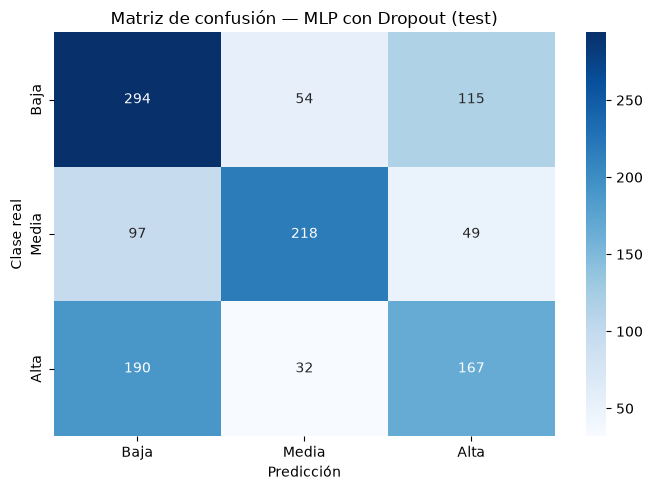

In [12]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1, 2])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de confusión — MLP con Dropout (test)')
plt.xlabel('Predicción'); plt.ylabel('Clase real'); plt.tight_layout(); plt.show()

## Cómo interpretar el resultado

Los cortes de Baja/Media/Alta son terciles aprendidos de grupos de entrenamiento, no umbrales clínicos. El dropout se aplica durante el entrenamiento para reducir sobreajuste; no garantiza mejores métricas. La evaluación sigue dependiendo del dataset aumentado y no es validación clínica.